In [ ]:
import marimo as mo

# Lluvia por contexto hidrográfico

Une las dos líneas del proyecto. El reporte hidrográfico (`notebooks/AAMM/09`,
`references/reporte_tecnico_hidrografico.pdf`) agrupó las colonias en cuatro contextos
según los cauces cercanos y encontró más reportes por km² junto a los colectores
principales. Su primera pregunta abierta fue: ¿es la red o solo la geografía? Los
notebooks 08 y 09 midieron cuánto suben las llamadas al 911 tras la lluvia. Aquí se
cruzan: si el contexto junto a colectores no solo tiene más llamadas, sino que sus
llamadas suben más cuando llueve, la red explica algo que la posición sola no explica.

- Contextos: `data/processed/inegi/hidrografia_hermosillo/colonias_contexto_hidrografico.csv`,
  que escribe `process_contexto_hidrografico_job` con `project_name/hydro_context.py`.
- Llamadas ubicadas: `colonia_id` de `add_colonia_llamada_job` (catálogo del INEGI más
  equivalencias revisadas a mano).
- Los baches solo entran en la comparación por lugar: la fecha del Bachómetro es la de
  atención, no la de aparición del bache.

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from project_name import water_events as we
from project_name.config import PROJECT_ROOT
from project_name.hydro_context import CONTEXT_NAMES
# Importar eda aplica el estilo de figuras del proyecto (fondo blanco, texto oscuro).
import project_name.eda  # noqa: F401

FIGURES = PROJECT_ROOT / "docs" / "img" / "contexto"
FIGURES.mkdir(parents=True, exist_ok=True)
INK, MUTED = "#0b0b0b", "#52514e"
# Colores del reporte hidrográfico, uno por contexto.
CONTEXT_COLORS = {0: "#4c78a8", 1: "#f58518", 2: "#9ca3af", 3: "#e45756"}
ALL_GROUPS = [
    "inundacion_directa",
    "terreno",
    "drenaje_y_red_de_agua",
    "fenomeno_hidrometeorologico",
]

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    return fig

In [ ]:
rain = we.load_rain()
colonias = we.load_colonias()
contexts = we.load_contexts()
calls = we.load_calls(colonias)
baches = we.load_baches_located(colonias)

## 1. Los cuatro contextos

Mismo método que `notebooks/AAMM/09`: los 3 cauces más cercanos al centroide, su orden
de Strahler y su nivel de corriente, y un nivel de cercanía; KMeans k = 4 con semilla
42. El código original de la libreta, corrido sobre los datos actuales, da la misma
asignación colonia por colonia que `hydro_context.py`.

In [ ]:
_area = we.context_area(colonias, contexts)
context_summary = pd.DataFrame(
    {
        "contexto": contexts.groupby("context")["context_name"].first(),
        "colonias": contexts.groupby("context").size(),
        "km²": _area.round(1),
        "colonias en el reporte hidrográfico": pd.Series({0: 186, 1: 161, 2: 180, 3: 235}),
        "km² en el reporte hidrográfico": pd.Series({0: 47.0, 1: 29.2, 2: 28.1, 3: 28.1}),
    }
)
profile = (
    contexts.groupby("context")[
        ["order_median", "order_max", "level_median", "level_min", "proximity_ord"]
    ]
    .mean()
    .round(2)
)
context_summary, profile

Lectura: los perfiles coinciden con los del reporte hidrográfico (el contexto 1 tiene
orden de Strahler cercano a 3.3; el 0 es el más lejano; el 2 tiene el nivel de
corriente más alto, arroyos de cabecera). Los tamaños difieren en pocas colonias
(183 contra 186, 160 contra 161, 173 contra 180, 246 contra 235): el reporte se calculó
sobre una corrida anterior de la red hidrográfica, con 428 tramos cercanos distintos
contra 427 hoy. Un empate de distancias resuelto de otra forma basta para mover
colonias de grupo en un agrupamiento sobre variables discretas.

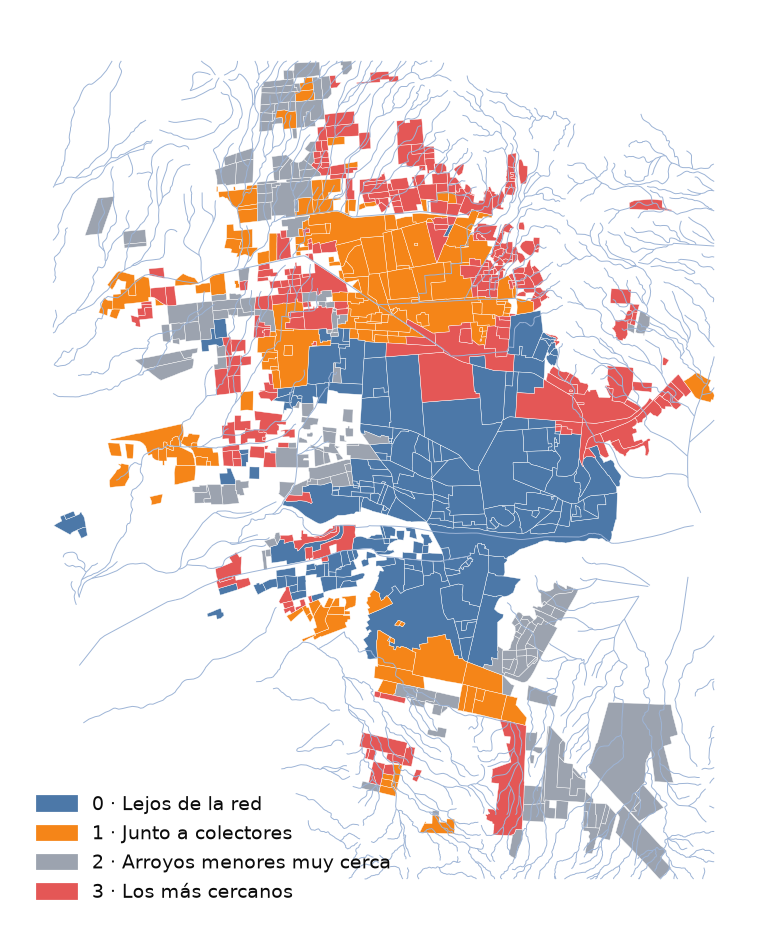

In [ ]:
_city = colonias.merge(contexts[["colonia_id", "context"]], on="colonia_id").to_crs(
    we.METRIC_CRS
)
_streams = gpd.read_file(we.SUBCUENCAS_FILE, layer="hl").to_crs(we.METRIC_CRS)
_streams = _streams[_streams.intersects(_city.union_all().buffer(1500))]
_fig, _ax = plt.subplots(figsize=(4.2, 4.8))
_streams.clip(_city.total_bounds).plot(ax=_ax, color="#9db4d6", linewidth=0.35)
for _c, _color in CONTEXT_COLORS.items():
    _city[_city["context"] == _c].plot(ax=_ax, color=_color, edgecolor="white", linewidth=0.15)
_handles = [plt.Rectangle((0, 0), 1, 1, color=_color) for _color in CONTEXT_COLORS.values()]
_ax.legend(
    _handles,
    [f"{_c} · {CONTEXT_NAMES[_c]}" for _c in CONTEXT_COLORS],
    fontsize=7,
    frameon=False,
    loc="lower left",
)
_ax.set_axis_off()
_fig.tight_layout()
save(_fig, "mapa_contextos")

## 2. Reportes por km² por contexto (control contra el reporte hidrográfico)

Avisos de Agua de Hermosillo (menciones de colonia más cruces geocodificados), llamadas
de los grupos de superficie (inundación directa y fenómeno hidrometeorológico) y baches,
divididos entre el área de cada contexto. Año completo y julio a septiembre.

In [ ]:
rates_year = we.context_rates(colonias, contexts, calls, baches)
rates_jas = we.context_rates(colonias, contexts, calls, baches, months=[7, 8, 9])
aamm_table3 = pd.DataFrame(
    {
        "avisos": [95, 175, 83, 136],
        "llamadas": [3.2, 4.3, 1.0, 2.4],
        "baches": [317, 305, 210, 301],
    }
)
rates_year.round(2), rates_jas.round(2), aamm_table3

In [ ]:
# Sensibilidad: fenomeno_hidrometeorologico solo existe en 2025 (cambio de catálogo).
rates_flood_only = we.context_rates(
    colonias, contexts, calls, baches, call_groups=["inundacion_directa"]
)
rates_flood_only["llamadas"].round(2)

,llamadas
context,
0.0,3.21
1.0,4.11
2.0,0.78
3.0,2.07


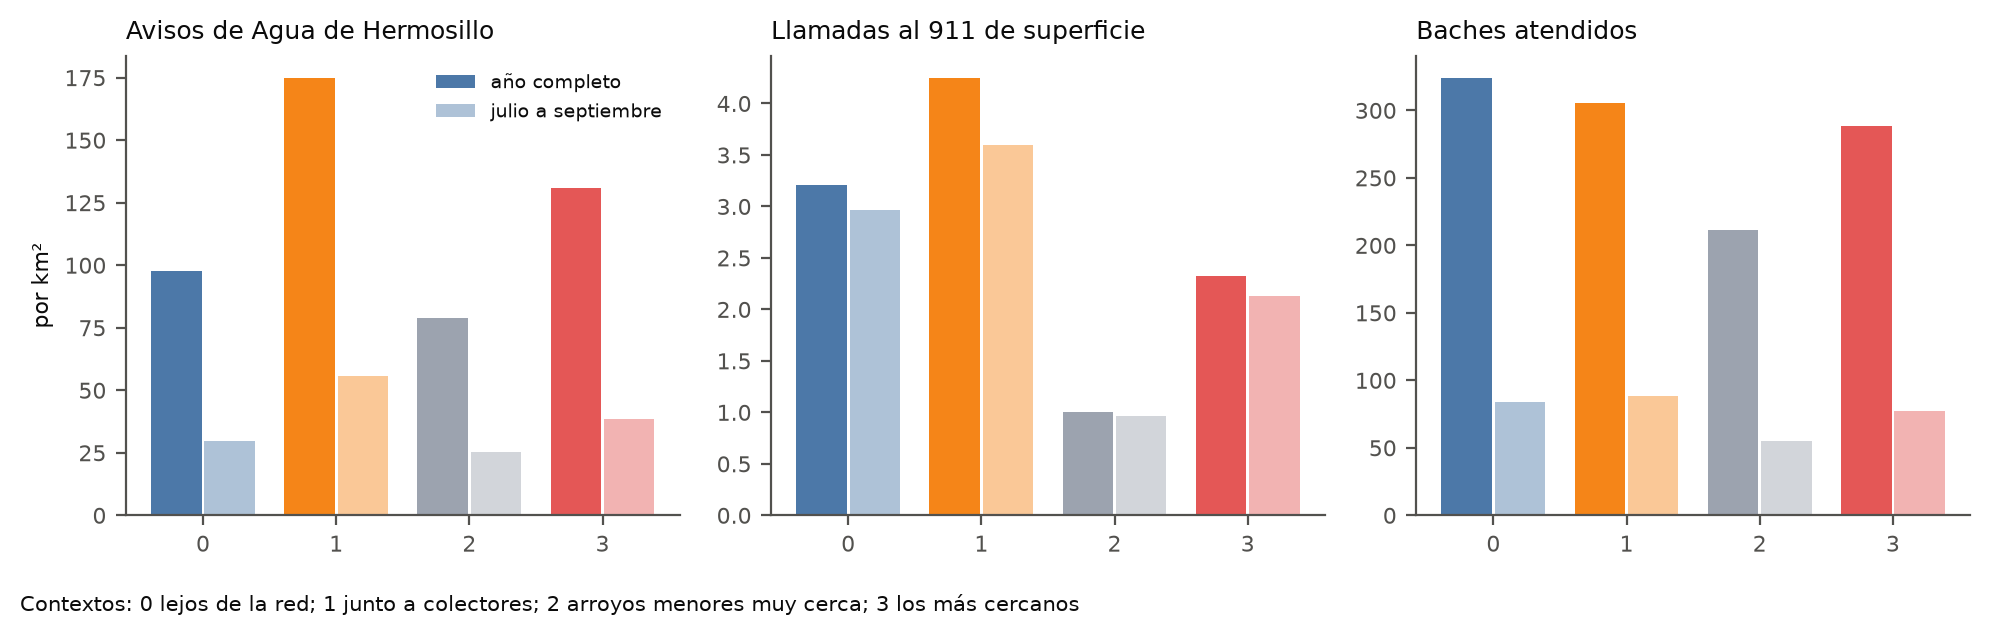

In [ ]:
_fig, _axes = plt.subplots(1, 3, figsize=(10, 3.0))
_titles = {
    "avisos": "Avisos de Agua de Hermosillo",
    "llamadas": "Llamadas al 911 de superficie",
    "baches": "Baches atendidos",
}
for _ax, _col in zip(_axes, ["avisos", "llamadas", "baches"]):
    _x = range(len(rates_year))
    _ax.bar(
        [_i - 0.2 for _i in _x],
        rates_year[_col],
        width=0.38,
        color=[CONTEXT_COLORS[int(_c)] for _c in rates_year.index],
        label="año completo",
    )
    _ax.bar(
        [_i + 0.2 for _i in _x],
        rates_jas[_col],
        width=0.38,
        color=[CONTEXT_COLORS[int(_c)] for _c in rates_jas.index],
        alpha=0.45,
        label="julio a septiembre",
    )
    _ax.set_xticks(list(_x), [str(int(_c)) for _c in rates_year.index], fontsize=8)
    _ax.set_title(_titles[_col], loc="left", fontsize=9, color=INK)
    _ax.spines[["top", "right"]].set_visible(False)
    _ax.tick_params(labelsize=8)
_axes[0].set_ylabel("por km²", fontsize=8)
_axes[0].legend(fontsize=7, frameon=False)
_fig.text(
    0.01,
    -0.04,
    "Contextos: " + "; ".join(f"{_c} {_n.lower()}" for _c, _n in CONTEXT_NAMES.items()),
    fontsize=7.5,
)
_fig.tight_layout()
save(_fig, "tasas_contexto")

Lectura: la réplica reproduce el reporte hidrográfico con diferencias de unas décimas
(por los tamaños de los contextos): el contexto 1, junto a colectores, lidera avisos y
llamadas por km² en el año, y en julio a septiembre lidera también los baches. Con solo
inundación directa el orden se mantiene. Esto dice dónde hay más reportes, no si
responden a la lluvia: eso es lo que mide la sección siguiente.

## 3. ¿Es la red o solo la geografía? Respuesta a la lluvia por contexto

Por contexto, conteo diario de las llamadas ubicadas ligadas a la lluvia (inundación,
terreno, drenaje y fenómeno hidrometeorológico). Dos comparaciones, como en el
notebook 08:

- Temporada: los 8 días que siguen a una lluvia de 10 mm o más contra los días secos de
  junio a octubre.
- Mismo mes: la misma comparación dentro de cada mes de cada año, que quita la
  temporada y la tendencia. Intervalo del 90% con bootstrap que remuestrea meses
  completos (los días de un mes no son independientes).

Si la razón es mayor junto a colectores, el contexto no solo tiene más llamadas: sus
llamadas responden más a la lluvia.

In [ ]:
def _response(groups):
    _series = we.context_daily_series(calls, contexts, groups)
    _daily = we.daily_table(rain, _series)
    _season = pd.DataFrame([we.event_study(_daily, _n) for _n in _series]).set_index("serie")
    _month = pd.DataFrame([we.within_month_interval(_daily, _n) for _n in _series]).set_index(
        "serie"
    )
    _season["llamadas"] = {_n: int(_s.sum()) for _n, _s in _series.items()}
    return (
        _season[["llamadas", "razón"]]
        .rename(columns={"razón": "razón temporada"})
        .join(_month[["razón en el mes", "intervalo 90% bajo", "intervalo 90% alto"]])
    )

response_all = _response(ALL_GROUPS)
response_ground = _response(["terreno"])
response_flood = _response(["inundacion_directa"])
response_all, response_ground, response_flood

/Users/enriquegiottonini/Code/mcd-all/proyecto-ingenieria-de-caracteristicas/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1406: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/Users/enriquegiottonini/Code/mcd-all/proyecto-ingenieria-de-caracteristicas/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1406: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


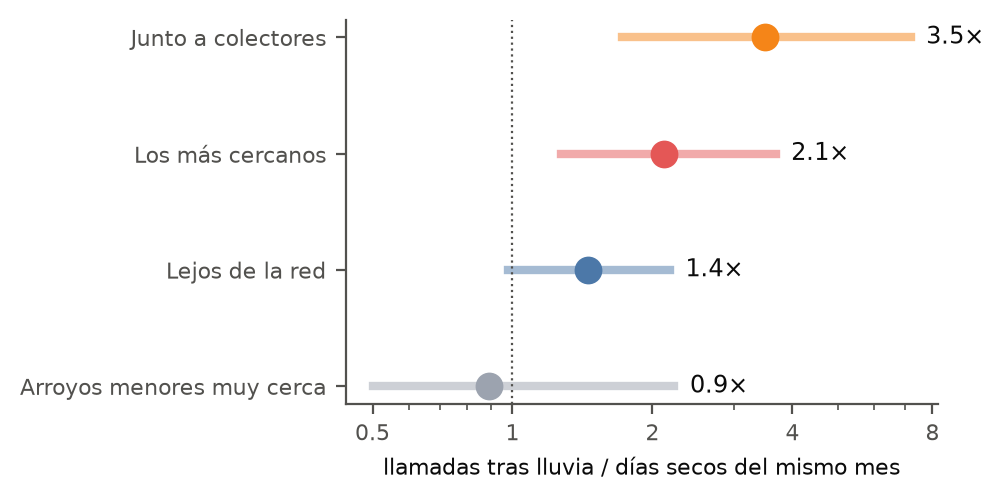

In [ ]:
_order = [CONTEXT_NAMES[_c] for _c in (2, 0, 3, 1)]
_rows = response_all.loc[_order]
_color_by_name = {CONTEXT_NAMES[_c]: CONTEXT_COLORS[_c] for _c in CONTEXT_NAMES}
_fig, _ax = plt.subplots(figsize=(5.2, 2.6))
for _y, (_name, _row) in enumerate(_rows.iterrows()):
    _ax.plot(
        [_row["intervalo 90% bajo"], _row["intervalo 90% alto"]],
        [_y, _y],
        color=_color_by_name[_name],
        linewidth=3,
        alpha=0.5,
    )
    _ax.plot(_row["razón en el mes"], _y, "o", color=_color_by_name[_name], markersize=9)
    _ax.text(
        _row["intervalo 90% alto"] * 1.08,
        _y,
        f"{_row['razón en el mes']:.1f}×",
        va="center",
        fontsize=8.5,
        color=INK,
    )
_ax.axvline(1, color=MUTED, linewidth=0.8, linestyle=":")
_ax.set_xscale("log")
_ax.xaxis.set_minor_formatter(plt.NullFormatter())
_ax.set_xticks([0.5, 1, 2, 4, 8], ["0.5", "1", "2", "4", "8"])
_ax.set_yticks(range(len(_order)), _order, fontsize=8.5)
_ax.set_xlabel("llamadas tras lluvia / días secos del mismo mes", fontsize=8)
_ax.spines[["top", "right"]].set_visible(False)
_ax.tick_params(labelsize=8)
_fig.tight_layout()
save(_fig, "respuesta_contexto")

## 4. Llamadas esperadas por contexto según la lluvia del día

Llamadas ubicadas ligadas a la lluvia, por día y por 100 km² de cada contexto, de junio
a octubre, según la lluvia del mismo día. Normalizar por área permite comparar contextos
de tamaño distinto.

In [ ]:
_area = we.context_area(colonias, contexts)
_context = contexts.set_index("colonia_id")["context"]
_located = calls[calls["grupo_incidente"].isin(ALL_GROUPS)].copy()
_located["context"] = _located["colonia_id"].map(_context)
intensity_by_context = pd.DataFrame(
    {
        int(_c): we.calls_by_intensity(rain, _located[_located["context"] == _c])["promedio"]
        / _area[_c]
        * 100
        for _c in sorted(_located["context"].dropna().unique())
    }
).round(2)
intensity_by_context.columns.name = "contexto (llamadas por día por 100 km²)"
intensity_by_context

contexto (llamadas por día por 100 km²),0,1,2,3
intensidad,,,,
seco (<1 mm),1.48,1.15,0.65,0.79
1 a 10 mm,4.65,3.25,2.11,2.07
10 a 20 mm,4.82,8.65,2.30,6.16
20 a 40 mm,16.72,9.26,2.23,7.12
40 mm o más,13.93,14.29,4.96,11.32


Lectura:

- Junto a colectores, las llamadas ligadas a la lluvia suben 3.5 veces dentro del mismo
  mes (intervalo del 90%: 1.7 a 7.2). Lejos de la red suben 1.4 veces (1.0 a 2.2), y en
  los arroyos menores no suben (0.9; 0.5 a 2.2). Los más cercanos quedan en medio (2.1;
  1.3 a 3.7).
- La red sí explica algo más que la geografía: el contexto de los colectores no solo
  tiene más llamadas por km², sus llamadas responden más a la lluvia. Los intervalos de
  colectores y de lejos de la red apenas se tocan, así que es evidencia moderada, no
  concluyente; con más años o una lluvia por zona se podría afinar.
- Las llamadas por inundación son pocas por contexto; la mayor parte cae lejos de la red
  (146 de 351 ubicadas), en el centro denso: la inundación urbana no depende solo del
  cauce natural, también del drenaje pluvial, que la red del INEGI no incluye.
- Los baches quedan fuera de esta parte: el Bachómetro registra atenciones (días
  hábiles, descripciones "Bacheo en…"), no cuándo aparece el bache.